In [ ]:
#Code with the topic: PCoA Principal Coordinates Analysis

#Objective:

#Implementation of PCoA from distance matrix calculation to visualization.

#Technologies:

#Pandas
#numpy
#Matplotlib
#seaborn

#Method used:

#PCoA





In [89]:
#We import the libraries:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import pdist, squareform



In [90]:
#Read the CSV file

data = pd.read_csv("PCoA_Principal_Coordinate_Analysis.csv")

In [ ]:
#Visualization 
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   sample  8 non-null      object 
 1   group   8 non-null      object 
 2   var1    8 non-null      int64  
 3   var2    8 non-null      int64  
 4   var3    8 non-null      int64  
 5   var4    8 non-null      int64  
 6   var5    7 non-null      float64
dtypes: float64(1), int64(4), object(2)
memory usage: 580.0+ bytes


In [92]:
data.describe()

,var1,var2,var3,var4,var5
count,8.00000,8.000000,8.000000,8.000000,7.000000
mean,20.50000,15.000000,19.625000,23.500000,21.000000
std,9.69536,3.927922,6.696214,7.578164,7.527727
min,10.00000,10.000000,12.000000,15.000000,14.000000
25%,11.75000,11.750000,13.750000,16.750000,15.000000
50%,20.50000,15.000000,19.500000,23.500000,16.000000
75%,29.25000,18.250000,25.250000,30.250000,28.500000
max,31.00000,20.000000,28.000000,32.000000,30.000000


In [93]:
data.head()

,sample,group,var1,var2,var3,var4,var5
0,s1,control,12,18,25,30,15.0
1,s2,control,10,20,28,29,16.0
2,s3,control,11,19,26,31,14.0
3,s4,treatmet,30,10,12,15,28.0
4,s5,treatment,28,12,14,17,30.0


In [ ]:
#Separate information


samples = data["sample"].astype(str)

groups = data["group"].astype(str)
# Numeric data only

X = data.drop(
    columns=["sample","group"]
)


X = X.apply(
    pd.to_numeric
)



In [ ]:
#Distance matrix


distance_matrix = squareform(
    pdist(
        X,
        metric="euclidean"
    )
)


print("\nDistance Matrix")
print(distance_matrix)


Distance Matrix
[[ 0.          4.35889894  2.23606798 30.83828789 28.40774542 30.757113
   2.64575131         nan]
 [ 4.35889894  0.          3.74165739 33.10589071 30.39736831 32.93933818
   6.63324958         nan]
 [ 2.23606798  3.74165739  0.         33.01514804 30.56141358 32.90896534
   3.74165739         nan]
 [30.83828789 33.10589071 33.01514804  0.          4.47213595  2.23606798
  30.65941943         nan]
 [28.40774542 30.39736831 30.56141358  4.47213595  0.          3.60555128
  28.28427125         nan]
 [30.757113   32.93933818 32.90896534  2.23606798  3.60555128  0.
  30.5450487          nan]
 [ 2.64575131  6.63324958  3.74165739 30.65941943 28.28427125 30.5450487
   0.                 nan]
 [        nan         nan         nan         nan         nan         nan
          nan  0.        ]]


In [ ]:
#Double centering


n = distance_matrix.shape[0]


D2 = distance_matrix ** 2


J = np.eye(n) - (
    np.ones((n,n))/n
)


B = -0.5 * J @ D2 @ J



# Make symmetric

B = (B + B.T) / 2




In [ ]:
#Eigen decomposition (stable version)

# Clean matrix
B = np.nan_to_num(B)

# Force symmetry
B = (B + B.T) / 2


# Check matrix
print("Matrix shape:", B.shape)
print("Matrix type:", B.dtype)


try:
    eigenvalues, eigenvectors = np.linalg.eigh(B)

except np.linalg.LinAlgError:

    print("eigh failed, using SVD method")

    U, S, Vt = np.linalg.svd(B)

    eigenvalues = S
    eigenvectors = U


# Sort eigenvalues descending

idx = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[idx]

eigenvectors = eigenvectors[:, idx]

Matrix shape: (8, 8)
Matrix type: float64


In [ ]:
#Principal coordinates


coordinates = (
    eigenvectors *
    np.sqrt(eigenvalues)
)



# Take first two axes

pcoa_results = pd.DataFrame(
    coordinates[:,0:2],
    columns=[
        "PC1",
        "PC2"
    ]
)



# Add metadata

pcoa_results["Sample"] = samples.values

pcoa_results["Group"] = groups.values



print("\nPCoA Results")
print(pcoa_results)






PCoA Results
   PC1  PC2 Sample      Group
0  0.0  0.0     s1    control
1  0.0  0.0     s2    control
2  0.0  0.0     s3    control
3  0.0  0.0     s4   treatmet
4  0.0  0.0     s5  treatment
5  0.0  0.0     s6  treatment
6  0.0  0.0     s7    control
7  0.0  0.0     s8  treatment



Explained variance
PC1: nan %
PC2: nan %


C:\Users\Selene\AppData\Local\Temp\ipykernel_7912\3068824819.py:6: RuntimeWarning: invalid value encountered in divide
  eigenvalues /


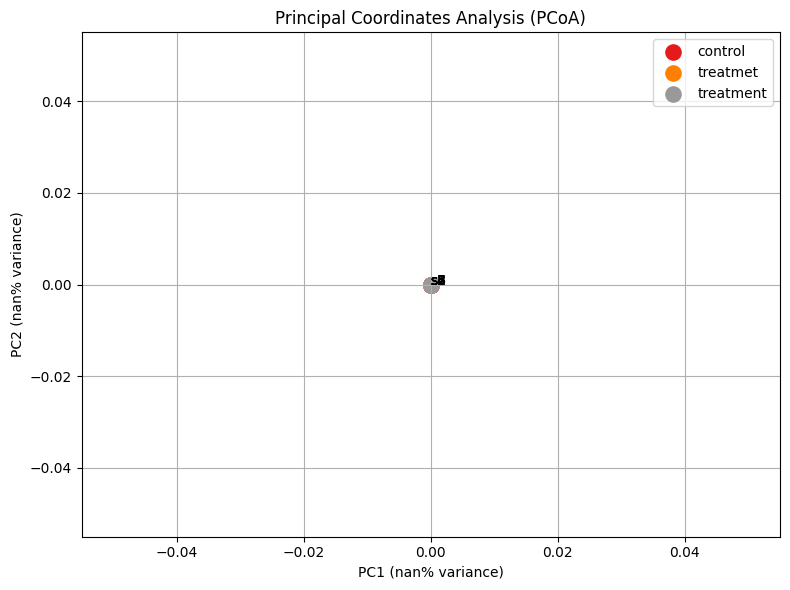

In [ ]:
# Explained variance



variance = (
    eigenvalues /
    eigenvalues.sum()
)



print("\nExplained variance")

print(
    "PC1:",
    round(variance[0]*100,2),
    "%"
)



#Plot PCoA



plt.figure(
    figsize=(8,6)
)


# Automatic colors

unique_groups = (
    pcoa_results["Group"]
    .unique()
)


colors = plt.cm.Set1(
    np.linspace(
        0,
        1,
        len(unique_groups)
    )
)



for group,color in zip(
    unique_groups,
    colors
):

    subset = pcoa_results[
        pcoa_results["Group"] == group
    ]


    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        s=120,
        color=color,
        label=group
    )



# Labels

for _,row in pcoa_results.iterrows():

    plt.annotate(
        row["Sample"],
        (
            row["PC1"],
            row["PC2"]
        ),
        fontsize=10
    )



plt.xlabel(
    f"PC1 ({variance[0]*100:.2f}% variance)"
)


plt.ylabel(
    f"PC2 ({variance[1]*100:.2f}% variance)"
)


plt.title(
    "Principal Coordinates Analysis (PCoA)"
)


plt.legend()

plt.grid(True)

plt.tight_layout()


plt.show()